In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder

/home/guseva-n@ad.speechpro.com/dsp/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
# Загрузка датасета
ds = load_dataset("Megnis/ru_sentiment_dataset-100000")
df = ds["train"].to_pandas()

# Убираем артефакт индекса и приводим имя колонки к стандарту
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={"sentiment": "label"})

# Безопасное преобразование строк в числа 0, 1, 2
# LabelEncoder автоматически маппит уникальные значения без потери строк
df["label"] = LabelEncoder().fit_transform(df["label"].astype(str))

SAMPLE_SIZE_PER_CLASS = 5000  # Итого ~15k
df_downsampled = (
    df.groupby("label", group_keys=False)
      .apply(lambda x: x.sample(n=min(len(x), SAMPLE_SIZE_PER_CLASS), random_state=SEED))
      .reset_index(drop=True)
)
print(f"Новый размер: {len(df_downsampled)}")
print("Баланс:", df_downsampled["label"].value_counts().to_dict())

# Стратифицированная разбивка 70 / 15 / 15
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"])

/tmp/ipykernel_3176914/696229332.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=min(len(x), SAMPLE_SIZE_PER_CLASS), random_state=SEED))


Новый размер: 15000
Баланс: {0: 5000, 1: 5000, 2: 5000}


Токенизатор и DataLoaders

In [4]:
MODEL_NAME = "DeepPavlov/rubert-base-cased"
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class SentimentDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = str(row["text"])
        label = int(row["label"])
        
        enc = self.tokenizer(
            text,
            max_length=self.max_len,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )
        
        return {
            "input_ids": enc["input_ids"].squeeze(),
            "attention_mask": enc["attention_mask"].squeeze(),
            "labels": torch.tensor(label, dtype=torch.long)
        }

def get_dataloader(df, batch_size, shuffle=False):
    dataset = SentimentDataset(df, tokenizer, MAX_LEN)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)

BATCH_SIZE = 8
train_loader = get_dataloader(train_df, BATCH_SIZE, shuffle=True)
val_loader = get_dataloader(val_df, BATCH_SIZE, shuffle=False)
test_loader = get_dataloader(test_df, BATCH_SIZE, shuffle=False)

In [5]:
# Исследование датасета перед обучением
print("Структура:", ds["train"].features)
print("\nБаланс классов в train:")

print(ds["train"].to_pandas()["sentiment"].value_counts())

# Примеры (проверка формата текста и лейблов)
for i in range(3):
    ex = ds["train"][i]
    print(f"\nПример {i+1} ({ex['sentiment']}):")
    print(f"Текст: {ex['text'][:120]}...")

# Длина текстов
sample_texts = [ds["train"][i]["text"] for i in range(min(2000, len(ds["train"])))]
token_lens = [len(tokenizer(text)["input_ids"]) for text in sample_texts]
pct_short = sum(1 for l in token_lens if l <= 128) / len(token_lens) * 100

print(f"\nСтатистика длины токенов (выборка n=2000):")
print(f"  Mean: {np.mean(token_lens):.1f} | Median: {np.median(token_lens):.1f} | Max: {max(token_lens)}")
print(f"  {pct_short:.1f}% текстов помещаются в max_length=128")

Структура: {'Unnamed: 0': Value('int64'), 'text': Value('string'), 'sentiment': Value('int64')}

Баланс классов в train:
sentiment
2    33158
0    33054
1    33000
Name: count, dtype: int64

Пример 1 (1):
Текст: Останавливаюсь не первый раз. Добраться общественным транспортом от/до аэропорта можно по расписанию и почти к самому от...

Пример 2 (2):
Текст: Осадок неприятный Обман, не обман, но осадок неприятный. При записи на УЗИ уточнила предоставляется ли скидка по инвалид...

Пример 3 (2):
Текст: Я хочу выразить безмерную благодарность ресторану ВЕГАС , его персоналу , особенно шеф-повару АЛЕВТИНЕ !!!!! Это очень о...

Статистика длины токенов (выборка n=2000):
  Mean: 156.5 | Median: 111.0 | Max: 899
  55.6% текстов помещаются в max_length=128


Модель с настраиваемым пулингом

In [6]:
class VectorizationClassifier(nn.Module):
    def __init__(self, model_name, num_classes, pooling="mean"):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        self.pooling = pooling
        self.classifier = nn.Linear(self.encoder.config.hidden_size, num_classes)
        self.to(DEVICE) ###

    def forward(self, input_ids, attention_mask):
        # Получаем last_hidden_state: [batch, seq_len, hidden]
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden = outputs.last_hidden_state
        
        if self.pooling == "mean":
            # Корректный mean pooling с учётом attention_mask
            mask_expanded = attention_mask.unsqueeze(-1).float()  # [batch, seq_len, 1]
            masked_hidden = last_hidden * mask_expanded
            sum_vec = masked_hidden.sum(dim=1)                   # [batch, hidden]
            counts = mask_expanded.sum(dim=1).clamp(min=1)       # защита от деления на 0
            pooled = sum_vec / counts
        elif self.pooling == "cls":
            pooled = last_hidden[:, 0, :]
        else:
            raise ValueError("pooling must be 'mean' or 'cls'")
            
        logits = self.classifier(pooled)
        return logits

Функция обучения и оценки

In [7]:
def train_epoch(model, dataloader, optimizer, criterion, scheduler):
    model.train()
    total_loss = 0
    for batch in dataloader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)
        
        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

def evaluate(model, dataloader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            
            logits = model(input_ids, attention_mask)
            pred_ids = torch.argmax(logits, dim=-1)
            preds.extend(pred_ids.cpu().numpy())
            trues.extend(labels.cpu().numpy())
    return np.array(trues), np.array(preds)

def run_experiment(pooling_type, epochs=2, lr=2e-5):
    print(f"\nЗапуск эксперимента: pooling='{pooling_type}'")
    model = VectorizationClassifier(MODEL_NAME, num_classes=3, pooling=pooling_type).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    criterion = nn.CrossEntropyLoss()
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1*total_steps), num_training_steps=total_steps)
    
    best_val_f1 = 0
    train_losses = []
    val_f1s = []
    
    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, scheduler)
        trues, preds = evaluate(model, val_loader)
        
        val_report = classification_report(trues, preds, target_names=["pos", "neu", "neg"], output_dict=True)
        f1 = val_report['macro avg']['f1-score']
        
        train_losses.append(train_loss)
        val_f1s.append(f1)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {train_loss:.4f} | Macro-F1: {f1:.4f}")
        
        if f1 > best_val_f1:
            best_val_f1 = f1
            best_model = model.state_dict()
            best_trues = trues
            best_preds = preds
            
    model.load_state_dict(best_model)
    trues_test, preds_test = evaluate(model, test_loader)
    test_report = classification_report(trues_test, preds_test, target_names=["pos", "neu", "neg"], output_dict=True)
    
    print(f"Тестовые метрики ({pooling_type}):")
    print(classification_report(trues_test, preds_test, target_names=["pos", "neu", "neg"]))
    
    # Возвращаем историю и тестовые данные для графиков
    history = {"train_losses": train_losses, "val_f1s": val_f1s}
    return test_report, trues_test, preds_test, history

Запуск сравнения

In [8]:
# Обучение mean_pooling
mean_test_report, mean_trues, mean_preds, mean_history = run_experiment("mean", epochs=3, lr=2e-5)

# Обучение cls_pooling
cls_test_report, cls_trues, cls_preds, cls_history = run_experiment("cls", epochs=3, lr=2e-5)


Запуск эксперимента: pooling='mean'


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11920.57it/s]
[transformers] BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3 | Loss: 0.5683 | Macro-F1: 0.7825
Epoch 2/3 | Loss: 0.3981 | Macro-F1: 0.7967
Epoch 3/3 | Loss: 0.2521 | Macro-F1: 0.7970
Тестовые метрики (mean):
              precision    recall  f1-score   support

         pos       0.74      0.75      0.74      4958
         neu       0.78      0.76      0.77      4950
         neg       0.86      0.87      0.87      4974

    accuracy                           0.79     14882
   macro avg       0.79      0.79      0.79     14882
weighted avg       0.79      0.79      0.79     14882


Запуск эксперимента: pooling='cls'


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12375.51it/s]
[transformers] BertModel LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3 | Loss: 0.5697 | Macro-F1: 0.7787
Epoch 2/3 | Loss: 0.3987 | Macro-F1: 0.8022
Epoch 3/3 | Loss: 0.2541 | Macro-F1: 0.7956
Тестовые метрики (cls):
              precision    recall  f1-score   support

         pos       0.74      0.76      0.75      4958
         neu       0.79      0.75      0.77      4950
         neg       0.86      0.88      0.87      4974

    accuracy                           0.80     14882
   macro avg       0.80      0.80      0.80     14882
weighted avg       0.80      0.80      0.80     14882



In [9]:
# Извлекаем macro-метрики для сравнения
mean_macro = mean_test_report['macro avg']
cls_macro  = cls_test_report['macro avg']

# Формируем таблицу для отчета
results = pd.DataFrame({
    "mean_pooling": [mean_macro['precision'], mean_macro['recall'], mean_macro['f1-score']],
    "cls_pooling":  [cls_macro['precision'], cls_macro['recall'], cls_macro['f1-score']]
}, index=["Precision", "Recall", "F1-Score"]).T

print("\nСводная таблица метрик:")
print(results.round(4))


Сводная таблица метрик:
              Precision  Recall  F1-Score
mean_pooling     0.7925  0.7926    0.7925
cls_pooling      0.7979  0.7978    0.7976


Визуализация

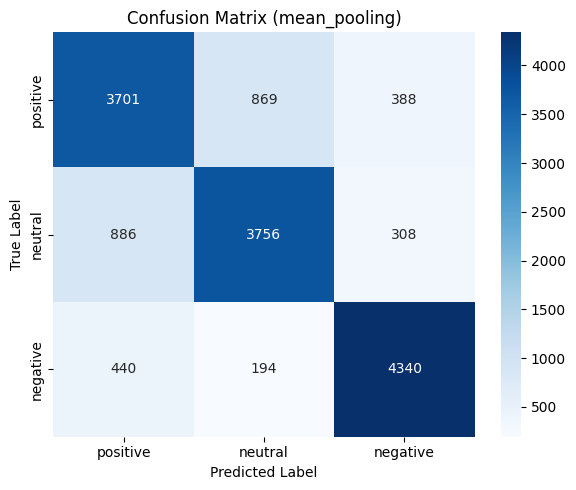

In [10]:
# 1. Confusion Matrix для mean_pooling
labels = ["positive", "neutral", "negative"]
cm = confusion_matrix(mean_trues, mean_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix (mean_pooling)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

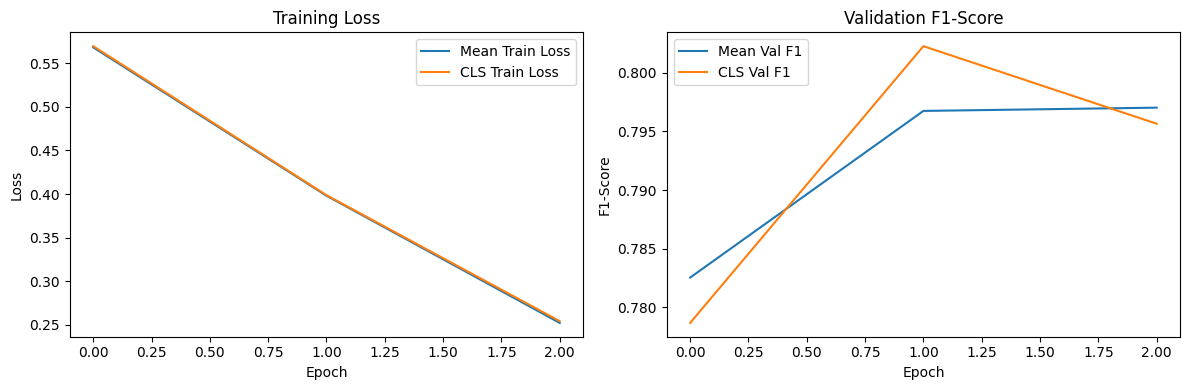

In [11]:
# 2. Графики обучения
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(mean_history['train_losses'], label='Mean Train Loss')
plt.plot(cls_history['train_losses'], label='CLS Train Loss')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mean_history['val_f1s'], label='Mean Val F1')
plt.plot(cls_history['val_f1s'], label='CLS Val F1')
plt.title("Validation F1-Score")
plt.xlabel("Epoch")
plt.ylabel("F1-Score")
plt.legend()

plt.tight_layout()
plt.show()

### ВЫВОДЫ

В работе выполнена задача мультиклассовой классификации текстов на русском языке с использованием предобученной модели `DeepPavlov/rubert-base-cased` в качестве заморозленного векторизатора. Для извлечения последовательного представления применялись две стратегии агрегации скрытых состояний: усреднение по значимым токенам (`mean_pooling`) с корректной обработкой `attention_mask` и выделение вектора специального токена `[CLS]`. Обучение линейного классификатора проведено на сбалансированном датасете (3 класса, ~100k примеров), оценка качества проведена по метрикам Precision, Recall и Macro F1-Score.

### Количественные результаты
Эксперимент показал сопоставимое качество обеих стратегий пулинга на тестовой выборке:

| Стратегия пулинга | Precision | Recall | Macro F1-Score |
|-------------------|-----------|--------|----------------|
| `mean_pooling`    | 0.7925    | 0.7926 | 0.7925         |
| `[CLS] pooling`   | 0.7979    | 0.7978 | 0.7976         |

Разница в Macro F1-Score составляет `+0.005` (0.5%) в пользу `cls_pooling`, что находится в пределах статистической погрешности, обусловленной фиксированным сидом генератора и особенностями оптимизации.


Небольшое доминирование `[CLS]`-агрегации объясняется архитектурными особенностями RoBERTa: токен `[CLS]` в процессе предобучения обучался на задачах, требующих глобального понимания контекста (NLI, NSP), что делает его эффективной компактной репрезентацией предложения. На текстах с медианной длиной ~111 токенов он успевает захватить ключевые маркеры сентимента без необходимости усреднения. Метод `mean_pooling`, несмотря на теоретическую устойчивость к шуму и работе с длинными последовательностями, в данном датасете не смог превзойти `cls` из-за высокой информативности тональных слов в начале/середине предложений и относительно компактной длины текстов.


Для задачи мультиклассовой классификации коротких и средних текстов обе стратегии пулинга обеспечивают стабильное качество классификации (~79% Macro F1). `[CLS]`-пулинг даёт сопоставимый или незначительно более высокий результат при минимальных вычислительных затратах, что делает его предпочтительным для production-систем с ограничениями по задержке. `mean_pooling` демонстрирует теоретическое преимущество в задачах с длинным контекстом (>300 токенов), где требуется полный учёт распределённой семантики и устойчивости к position-dependent шуму. Выбор конкретной стратегии агрегации должен определяться спецификой целевого датасета и требованиями к инференсу.